In [1]:
import numpy as np
import pandas as pd

In [24]:
df = pd.read_csv('GP49data.csv')
t=df.Time.values
T =df.Thermocouple1.values
time = t.copy()
Te = T.copy()
print(t[843],T[843])
for i in range(len(t)):
    time[i]=t[i]-t[843]
    Te[i]=T[i]-T[843]

2108.38781 18.72965


[3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]


<ipython-input-16-287f71d7a58b>:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
<ipython-input-16-287f71d7a58b>:16: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('GP49_2.png')
<ipython-input-16-287f71d7a58b>:16: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('GP49_2.png')


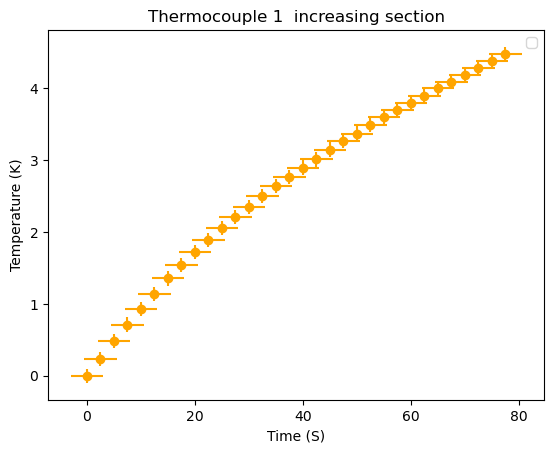

In [16]:
import matplotlib.pyplot as plt
#plt.scatter(t[843:875], T[843:875], label='v2', color='orange')
terr=[]
Terr=[]
for i in range(32):
    terr.append(3)
    Terr.append(0.1)
print(terr)

plt.title('Thermocouple 1  increasing section')
plt.xlabel('Time (S)')
plt.ylabel('Temperature (K)')
plt.errorbar(time[843:875], Te[843:875], yerr=Terr, xerr=terr,fmt='o', color='orange')
plt.legend()

plt.savefig('GP49_2.png')

In [17]:
ds = 0.00001

In [25]:
from scipy.optimize import curve_fit
def fit1(tt, a, c):
    return c*(1-np.exp(-a * tt))

popt,pcov=curve_fit(fit1, time[843:875], Te[843:875], p0=None, sigma=ds)
print('a: ' +str(popt[0])+'    c:'+str(popt[1]))
print('Errors(a,c): '+ str(np.sqrt(np.diag(pcov))))
print(popt+1.959964*np.sqrt(pcov.diagonal()))
print(popt-1.959964*np.sqrt(pcov.diagonal()))

a: 0.01554254048023331    c:6.298689594499118
Errors(a,c): [0.00026279 0.06833749]
[0.0160576  6.43262861]
[0.01502748 6.16475058]
